# Counting Communities (Group 20)

- Alexandra Ignatova (2100290)

## 1. Introduction



### 1.1. Definition of Communities

The communities of a given network $G = ([n], E)$ are formally defined as a partition of the vertices s.t. 

1. $\mathcal{C} \coloneqq \{C_1, \ldots, C_k\}$ where $C_i \subseteq [n] \forall i \in [k]$ 
2. $\forall i, j \in [k],\ i \neq j: C_i \cap C_j = \emptyset$
3. $\bigcup_{i = 1}^{k} C_i = [n]$

Furthermore, for random graphs like the **Stochastic Block Model**, the *intra*-community edge probability must be greater or equal to the *inter*-community edge probability. For SBM, this is formally expressed as:

$$ Q \in [0, 1]^{k \times k}:\ q_{ij} \coloneqq \mathbb{P}(\{u, v\} \in E),\quad u \in C_i,\ v \in C_j $$

where the following condition is satisfied:

$$ \forall i \in [k]: q_{ii} \geq q_{ij}\ \forall j \in [k] \setminus \{i\} \quad \quad (*)$$

In particular, to design a Community Detection Algorithm we need a procedure that can ensure we satisfy $(*)$. When working with real-life networks we don't have access to those probabilities and they are likely not as straightforward. For this reason, we focus on the vertex degrees and analyzing more densely connected components vs weakly connected spots in the network. 

### 1.2. Equivalent Characterization

For a deterministic graph $G = ([v], E)$ we can reason much the same way. `Communities are strongly connected within themselves and weakly connected to other communities.` In practice, if we define for each $v \in [n]$ apart of community $C_i$:

$$ d_v^{\text{intra}} \coloneqq | \{ \{u, v\} \in E: u \in C_i \} |, \quad \quad d_v^{\text{inter}} \coloneqq | \{ \{u, v\} \in E: u \notin C_i \} |, $$

then we can write an analogical statement to $(*)$, which says that:

$$ \forall v \in [n]: d_{v}^{\text{intra}} \geq d_{v}^{\text{inter}} (**)$$

Indeed, then it must be true that a vertex shares more neighbours with the vertices from its own community, and less so with vertices outside of its community. Let $A \in \{0, 1\}^{n \times n}$ be the adjacency matrix of a simple graph $G$. Then, we define a matrix $M \in \{-1, 0, \ldots, n - 2\}^{n \times n}$, given element-wise by:

$$ \forall i, j \in [n]: m_{ij} \coloneqq 
    \begin{cases}
        -1, & a_{ij} = 0 \\
        |N(i) \cap N(j)|, & a_{ij} = 1
    \end{cases}
$$

Esentially the matrix $M$ returns $-1$ whenever two nodes are not adjacent and the number of common neighbours they have, if they are adjacent. The reason we decide to set non-adjacent pairs in M to $-1$ is so that we can satisfy condition $(**)$ with our procedure, explained in the next section.

In [47]:
# load libraries
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os, requests, zipfile, gzip, io
from scipy.stats import poisson
from types import SimpleNamespace
from scipy.sparse import coo_matrix
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import SpectralClustering



SEED = 2026

DATASETS = "data"
os.makedirs(DATASETS, exist_ok=True)

WEAVER_URL = "https://nrvis.com/download/data/dynamic/aves-weaver-social.zip"

def download(url, file_name):
    path = os.path.join(DATASETS, file_name)
    if not os.path.exists(path):
        print(f"downloading {file_name} ...")
        try:
            req = requests.get(url)
            req.raise_for_status() # in case of errors

            with open(path, 'wb') as f:
                f.write(req.content)

        except Exception as error:
            if os.path.exists(path):
                os.remove(path) # clean corrupted install
            raise RuntimeError(f"Graph download failed : {error}. If it continues to fail, download them by hand and save them in a 'data' folder in the root directory")

    return path

def csv_path(name):
    return os.path.join(DATASETS, name)

def save_edges(G, file_name):
    nx.to_pandas_edgelist(G)[["source", "target"]].to_csv(csv_path(file_name), index=False)

def read_edges(file_name, nodes=None):
    edges = pd.read_csv(csv_path(file_name), keep_default_na=False)
    G = nx.Graph()
    if nodes is not None:
        G.add_nodes_from(nodes)
    G.add_edges_from(zip(edges["source"], edges["target"]))
    return G

def load_weaver():
    # 3-column edge list: source, target, timestamp -> collapse to static undirected graph
    cached = "aves_weaver_social_edges.csv"
    if not os.path.exists(csv_path(cached)):
        zipped_folder = zipfile.ZipFile(download(WEAVER_URL, "aves-weaver-social.zip"))
        edges = pd.read_csv(
            io.BytesIO(zipped_folder.read("aves-weaver-social.edges")),
            header=None,
            sep=r"\s+", engine='python', comment="#", 
            names=["source", "target", "timestamp"]
        )
        # same pair may interact many times; keep each unique undirected edge once
        lo = edges[["source", "target"]].min(axis=1)
        hi = edges[["source", "target"]].max(axis=1)
        pairs = pd.DataFrame({"source": lo, "target": hi}) \
            .query("source != target") \
            .drop_duplicates()
        pairs.to_csv(csv_path(cached), index=False)
    return read_edges(cached)

weaver = load_weaver()
print("Weaver : ", weaver)

Weaver :  Graph with 445 nodes and 1332 edges


## 2. Community Count Estimator


### 2.1 Community Detection Algorithm

Our proposed method estimates the number of communities by examining the similarity between the neighborhoods of adjacent vertex pairs. The underlying assumption is that vertices belonging to the same community are more likely to share other neighbours than vertices belonging to different communities. This is particularly relevant for social networks, where individuals within the same group may have several mutual connections. This is similar to the definitions laid out in Section 1.2; however, for practical purposes we propose an algorithmically equivalent way of expressing $M$ which exploits the sparsity of large networks.

For a graph $G = ([n], E)$, let $N(v)$ denote the set of neighbors of vertex $v$. We construct a similarity matrix $M$, where each off-diagonal entry represents the number of common neighbours between two vertices if and only if they are adjacent:

$$
M_{ij} = |N(i) \cap N(j)| \times \mathbb{1}_{\{i, j\} \in E}, \qquad i, j \in [n]\ \text{s.t.}\ i \neq j,
$$

with $M_{ii} = 0$.

For an undirected graph with adjacency matrix $A$, the similarity matrix can be calculated efficiently using

$$
M = (A^2) * A,\quad \text{where * is the element-wise multiplication}
$$

after setting the diagonal entries to zero. The entry $(A^2)_{ij}$ counts the number of walks of length two between vertices $i$ and $j$, which is equal to the number of common neighbours between them in a simple undirected graph. Then multiplying with $a_{ij}$ guarantees that they are adjacent as well.

We introduce a similarity threshold $\tau$ to determine whether two vertices should be assigned to the same community. If for a vertex $i \in [n]$, we introduce permutation $\mu_i: [n] \to [n]$ such that:

$$
M_{i \mu_{i}(1)} \geq \ldots \geq M_{i \mu_{i}(n)},\ \text{and}\ \forall j \in [n]\ \text{s.t.}\ \mu_{i}(j) \leq d_i \implies a_{ij} = 1,
$$

meaning that the first $d_v$ elements are necessarily the neighbours of $v$. Then we can define $\tau$ to be the deciding cut-out of same community assignment for this vector so that generally a vertex $v \in [n]$ will connect with $\lceil \tau d_v \rceil$ number of vertices. To make the condition $(**)$ hold, we would require $\tau \in [0.5,\ 1]$. Formally, if we define a labelling map $\hat{\sigma}: [n] \to K$ for some $1 \leq K \leq n$ (more broadly we can define $\hat{\sigma}: [n] to \{1, \ldots, n\}$; however, we decide to stick with the arbitrary $K$ for the sake of simplicity) we assign:

$$
\forall u \in [n] \setminus \{v\} \hat{\sigma}(u) = \hat{\sigma}(v)\ \text{if}\ \mu_{v}(u) \leq \lceil \tau d_v \rceil
$$

Alternatively, we can implement the same idea without ordering the non-neighbours and neighbours in $\mu_{v}$ if we update the assignment condition to be $\{ \mu_{v}(u) \leq \lceil \tau d_v \rceil \} \land \{ M_{uv} > 0 \}$ which intuitively makes more sense as assigning the same community to adjacent vertices with no common neighbours does not make for a good community detection algorithm. In that sense despite the threshold we still might have vertices which are connected to many vertices with whom they have no common neighbours, and they might end up, in the case of our algorithm, as singleton communities.

Finally, note that while the condition of the community assignment is sufficient to show two vertices belong to the same community, it is not necessary as they might end up in the same class due to proximity with some third highly connected vertex. For this reason we introduct a similarity graph $S = ([n], E_S)$ so that

$$
\forall u, v \in [n]: S_{uv} = \begin{cases} 1, & \{ \mu_{v}(u) \leq \lceil \tau d_v \rceil \} \land \{ M_{uv} > 0 \} \\ 0, & \text{else} \end{cases}
$$


We then interprate the connected components of this graph to be the estimated communities, and their number provides our estimate of the number of communities in the original network.

The choice of threshold is important. A low threshold may connect otherwise distinct communities, while a high threshold may split communities into smaller groups or isolate individual vertices. We therefore investigate the behavior of the estimator across different thresholds and evaluate its performance using stochastic block models with known community structures.


In [51]:
# Community count estimator based on common neighbors

def common_neighbor_matrix(G):
    """Compute the number of common neighbours for each adjacent pair."""
    A = nx.to_scipy_sparse_array(
        G, format="csr", dtype=np.int64
    )

    M = (A @ A).multiply(A)

    # Remove diagonal efficiently
    M = M.tocoo()
    mask = M.row != M.col

    M = csr_matrix(
        (M.data[mask], (M.row[mask], M.col[mask])),
        shape=M.shape
    )

    return M

def estimate_communities(G, tau=0.5):
    """Estimate communities using common-neighbour similarity."""
    M = common_neighbor_matrix(G).tocsr()

    # Row sums of A give degrees in M's node order
    A = nx.to_scipy_sparse_array(G, format="csr", dtype=np.int64)
    degrees = np.asarray(A.sum(axis=1)).ravel()

    rows, cols = [], []
    for v in range(M.shape[0]):
        # slice i-th row vector of M to determine non-zero values 
        start, end = M.indptr[v], M.indptr[v + 1]

        # v keeps its top ceil(tau * d_v) neighbours by common-neighbour count
        k = min(int(np.ceil(tau * degrees[v])), end - start) # number of vertices which will connect to v
        if k <= 0:
            continue

        idx = M.indices[start:end]   # neighbours u with M_uv > 0
        dat = M.data[start:end]

        keep = idx if k == end - start else idx[np.argpartition(-dat, k - 1)[:k]] # add first k largest values

        rows.extend([v] * len(keep)) # add source vertex for each remaining edge in S
        cols.extend(keep) # add target vertex for each remaining edge in S

    S = csr_matrix(
        (np.ones(len(rows), dtype=np.int8), (rows, cols)),
        shape=M.shape,
    )

    n_communities, labels = connected_components(S, directed=False)
    return n_communities, labels

for tau in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    n_communities, labels = estimate_communities(weaver, tau=tau)
    sizes = np.bincount(labels)
    print(f"tau = {tau}: {n_communities} communities "
          f"(singletons={(sizes == 1).sum()}, largest={sizes.max()})")


tau = 0.5: 79 communities (singletons=50, largest=78)
tau = 0.6: 77 communities (singletons=50, largest=86)
tau = 0.7: 74 communities (singletons=50, largest=90)
tau = 0.8: 74 communities (singletons=50, largest=90)
tau = 0.9: 74 communities (singletons=50, largest=90)
tau = 1.0: 74 communities (singletons=50, largest=90)


### 2.2. Threshold Sensitivity Analysis

The number of detected communities depends on the similarity parameter $\tau$. Increasing $\tau$ adds edges to the similarity graph, potentially merging communities into larger components. To investigate this behaviour, we examine the number and sizes of communities across the sweep $\tau \in [0.5, 1.0]$ and specifically tracking the number of singleton communities which likely form due to the lack on neighbours who have common neighbours with them as well. With this, our goals are first to see if our metric exhibits stable behaviour with the variation of $\tau$ and second to track the prevalence of singletons. 

We predict that singletons likely occur due to leaves or corners whose neighbours are non-adjacent. It might be interesting to consider merging such singleton communities if all of their neighbours lay in the same or predominantly the same community.

In [54]:
# Analyze community sizes for different taus

taus = np.linspace(0.5, 1.0, 11)

tau_results = []

for t in taus:
    n_comm, labels = estimate_communities(weaver, tau=t)

    sizes = np.bincount(labels)

    tau_results.append({
        "tau": round(float(t), 2),
        "Communities": n_comm,
        "Singletons": np.sum(sizes == 1),
        "Largest community": sizes.max(),
        "Mean community size": sizes.mean(),
        "Median community size": np.median(sizes)
    })

tau_df = pd.DataFrame(tau_results)

display(tau_df)

,tau,Communities,Singletons,Largest community,Mean community size,Median community size
0,0.50,79,50,78,5.632911,1.0
1,0.55,77,50,86,5.779221,1.0
2,0.60,77,50,86,5.779221,1.0
3,0.65,74,50,90,6.013514,1.0
4,0.70,74,50,90,6.013514,1.0
5,0.75,74,50,90,6.013514,1.0
6,0.80,74,50,90,6.013514,1.0
7,0.85,74,50,90,6.013514,1.0
8,0.90,74,50,90,6.013514,1.0
9,0.95,74,50,90,6.013514,1.0


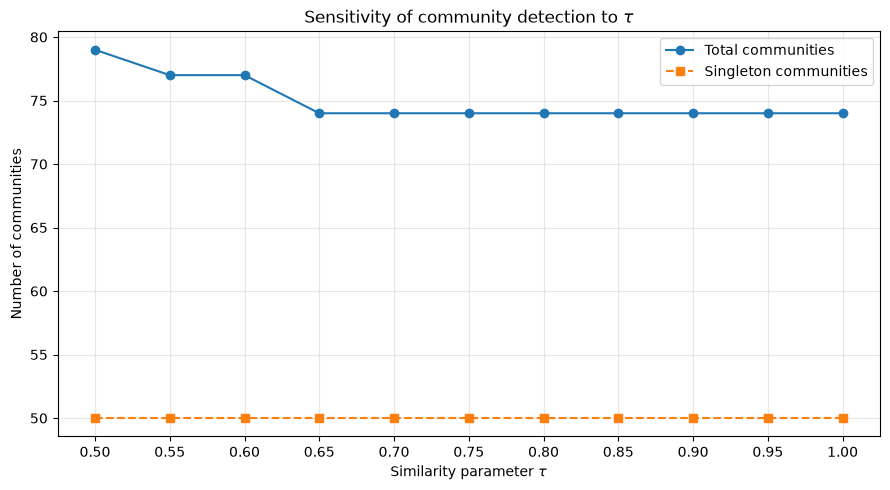

In [55]:
plt.figure(figsize=(9, 5))

plt.plot(
    tau_df["tau"],
    tau_df["Communities"],
    "o-", label="Total communities"
)

plt.plot(
    tau_df["tau"],
    tau_df["Singletons"],
    "s--", label="Singleton communities"
)

plt.xlabel(r"Similarity parameter $\tau$")
plt.ylabel("Number of communities")
plt.title(r"Sensitivity of community detection to $\tau$")
plt.xticks(taus)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Indeed, we observe that a great part of these communities are singletons, which we try to mitigate by modifying our algorithm by applying an extra procedure to the labelling process, which we describe in detail in *Section 2.3*.

### 2.3. Singleton Merging & Proposed Improvement

The estimator of Section 2.1 assigns $u$ and $v$ to the same community only when $M_{uv} > 0$, that is, only when the two vertices are adjacent *and* share at least one common neighbour. This method completely overlooks the cases in which a vertex $v$ has pairwise non-adjacent neighbours such as leaves or corners whose neighbours are not connected by an edge. In both of those cases $M_{uv} = 0$ for every $u \in N(v)$. Those are the most common vertices for which our algorithm detects to be empty in their row in $M$ and thus, it places them in an isolated community regardless of $\tau$. Such vertices are systematically isolated by our algorithm and can never configure in a bigger community.

This observation motivates a refinement, specifically designed to tackle this issue. A singleton may be *unambiguously attached* to one surrounding community, even when all of its neighbours lack commonality. Since the neighbours may now all collectively belong to the same
class, we can likely deduce that this singleton is simple an edge case of said community. We formalise this with a **neighbour-label profile**. Given the labelling $\hat\sigma : [n] \to K$ produced by the estimation for a given $\tau$, define for each $v$ with $d_v > 0$

$$
\pi_v(c) \coloneqq \frac{\bigl|\{u \in N(v) : \hat\sigma(u) = c\}\bigr|}{d_v},
\qquad c \in [K],
$$

the fraction of $v$'s neighbourhood that lies in community $c$, and let

$$
\rho_v \coloneqq \max_{c \in [K]} \pi_v(c)
$$

be the label of the **dominant neighbour community label**: the largest share of $v$'s neighbours that agree on a single community. A value $\rho_v = 1$ means every neighbour of $v$ already sits in one class, whereas $\rho_v = 1 / d_v$ means $v$'s neighbours are all apart of different communities. The solution is a single reassignment rule. Given a **dominance parameter** $\rho \in [0, 1]$, we define the merge operator $M_\rho$: for every $v$ that is a singleton, s.t.

$$
\hat\sigma(v) \;\longleftarrow\; \arg\max_{c}\,\pi_v(c)
\qquad\text{whenever}\qquad
\rho_v \geq \rho .
$$

Virtually, this only affects singletons for which their neighbourhood is highly partial (above some critical $\rho$) to a particular label. This is similar to predicting that someone likes a certain football team, given most of their friends like it too, even though they don't personally know each other.

Because reassigning $v$ changes the label counts seen by other singletons, the operator is applied repeatedly until no further reassignment occurs. Note that the process terminates as each application dissolves one singleton, and dissolving a singleton can only increase $\rho_w$ for other singletons $w$, so the set of eligible vertices grows monotonically and the loop halts after at most $n$ steps. We acknowledge that a difference in choice of order of execution might lead to different labelling alltogether, but this is beyond the scope of this notebook.

This improvement is evaluated jointly with $\tau$ in *Section 2.4*, where the community count is swept over the full $(\tau,\rho)$ grid, and the resulting values are used in *Section 2.5* to select both parameters by invariance. Its behaviour on networks with planted structure is then examined in *Section 2.6*.

In [80]:
### Merge Singletons to Dominant Neighbouring Community ###

def merge_dominated_singletons(G, labels, dominance=0.5, max_iter=10):
    """
    Reassign singleton communities whose neighbours are dominated by a single other community. Returns (new_labels, n_reassigned).
    """
    A = nx.to_scipy_sparse_array(G, format="csr", dtype=np.int8)
    labels = labels.copy()
    total_moved = 0

    for _ in range(max_iter):
        sizes = np.bincount(labels)
        singletons = np.where(sizes[labels] == 1)[0]

        moved = 0
        for v in singletons:
            nb = A.indices[A.indptr[v]:A.indptr[v + 1]]
            if len(nb) == 0:
                continue

            vals, counts = np.unique(labels[nb], return_counts=True) 
            # get the numbers of all the unique labels of the singleton's neighbouring vertices
            top = counts.argmax()
            if counts[top] / len(nb) >= dominance and vals[top] != labels[v]:
                labels[v] = vals[top]
                moved += 1

        total_moved += moved
        if moved == 0:
            break

    return labels, total_moved

### Convert Labels to Vertex Sets ###

def community_vsets(labels, nodes = list(weaver.nodes())):
    out = {}
    for i, v in enumerate(nodes):
        out.setdefault(labels[i], set()).add(v)
    return list(out.values())

### Test Efficiency of Singleton Merging ###

merge_diag = []
for t in taus:
    n_comm, labels = estimate_communities(weaver, tau=t)

    # How many singletons have a dominant neighbouring community at all?
    A = nx.to_scipy_sparse_array(weaver, format="csr", dtype=np.int8)
    sizes = np.bincount(labels)
    singletons = np.where(sizes[labels] == 1)[0]
    eligible = 0
    for v in singletons:
        nb = A.indices[A.indptr[v]:A.indptr[v + 1]]
        if len(nb) == 0:
            continue
        _, counts = np.unique(labels[nb], return_counts=True)
        # How many actually pass the dominance threshold required to merge them?
        if counts.max() / len(nb) >= 0.5:
            eligible += 1

    merged_labels, n_moved = merge_dominated_singletons(weaver, labels)

    merge_diag.append({
        "tau": round(float(t), 2),
        "communities": n_comm,
        "singletons before": int(len(singletons)),
        "eligible for merge": eligible,
        "actually merged": n_moved,
        "communities after": len(set(merged_labels)),
        "Q before": nx.community.modularity(weaver, community_vsets(labels)),
        "Q after": nx.community.modularity(weaver, community_vsets(merged_labels)),
    })

merge_df = pd.DataFrame(merge_diag)
display(merge_df.round(4))

,tau,communities,singletons before,eligible for merge,actually merged,communities after,Q before,Q after
0,0.50,79,50,49,47,34,0.8394,0.8712
1,0.55,77,50,49,47,32,0.8376,0.8687
2,0.60,77,50,49,47,32,0.8376,0.8687
3,0.65,74,50,49,47,29,0.8241,0.8548
4,0.70,74,50,49,47,29,0.8241,0.8548
5,0.75,74,50,49,47,29,0.8241,0.8548
6,0.80,74,50,49,47,29,0.8241,0.8548
7,0.85,74,50,49,47,29,0.8241,0.8548
8,0.90,74,50,49,47,29,0.8241,0.8548
9,0.95,74,50,49,47,29,0.8241,0.8548


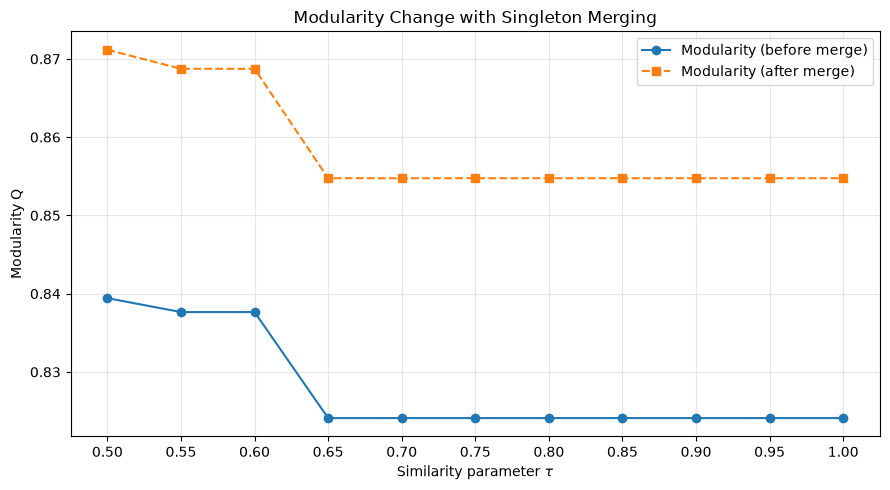

In [81]:
plt.figure(figsize=(9, 5))

plt.plot(
    tau_df["tau"],
    merge_df["Q before"],
    "o-", label="Modularity (before merge)"
)

plt.plot(
    tau_df["tau"],
    merge_df["Q after"],
    "s--", label="Modularity (after merge)"
)

plt.xlabel(r"Similarity parameter $\tau$")
plt.ylabel("Modularity Q")
plt.title(r"Modularity Change with Singleton Merging")
plt.xticks(taus)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 2.4. Parameter Dependance Analysis (threshold $\tau$ & dominance $\rho$)

The dependance on the parameters in so far has been somewhat arbitrary. For this reason, we investigate both by sweeping $\rho$ jointly with $\tau$ over the full grid and inspecting the resulting surface. If the community count is remains contsant across a broad range of $\rho$, the estimate is robust and the choice barely matters. If it varies steeply, the number of communities is not identifiable from the graph alone, and reporting a point estimate would be misleading.

In [82]:
### Joint sweep over (tau, rho) ###

nodes = list(weaver.nodes())
taus = np.linspace(0.5, 1.0, 11)
rhos = np.linspace(0.0, 1.0, 11)

grid_rows = []
for t in taus:
    n0, lab0 = estimate_communities(weaver, tau=float(t))
    for r in rhos:
        lab1, moved = merge_dominated_singletons(weaver, lab0, dominance=float(r))
        comms = community_vsets(lab1, nodes=nodes)
        sizes = np.array([len(c) for c in comms])
        grid_rows.append({
            "tau": round(float(t), 2),
            "rho": round(float(r), 2),
            "communities": len(comms),
            "singletons": int((sizes == 1).sum()),
            "merged": moved,
            "Q": nx.community.modularity(weaver, comms),
        })

grid_df = pd.DataFrame(grid_rows)

# Community count as a surface over (tau, rho)
surface = grid_df.pivot(index="rho", columns="tau", values="communities")
display(surface)

# Does the count vary much across rho, at each tau?
spread = surface.max(axis=0) - surface.min(axis=0)
# print("\nRange of community count across rho, per tau:")
# print(spread.round(1).to_string())
print(f"\nOverall spread across rho: min {spread.min()} to max {spread.max()} communities")

tau,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00
rho,,,,,,,,,,,
0.0,33,31,31,28,28,28,28,28,28,28,28
0.1,33,31,31,28,28,28,28,28,28,28,28
0.2,33,31,31,28,28,28,28,28,28,28,28
0.3,33,31,31,28,28,28,28,28,28,28,28
0.4,34,32,32,29,29,29,29,29,29,29,29
0.5,34,32,32,29,29,29,29,29,29,29,29
0.6,40,38,38,35,35,35,35,35,35,35,35
0.7,40,38,38,35,35,35,35,35,35,35,35
0.8,40,38,38,35,35,35,35,35,35,35,35



Overall spread across rho: min 7 to max 7 communities


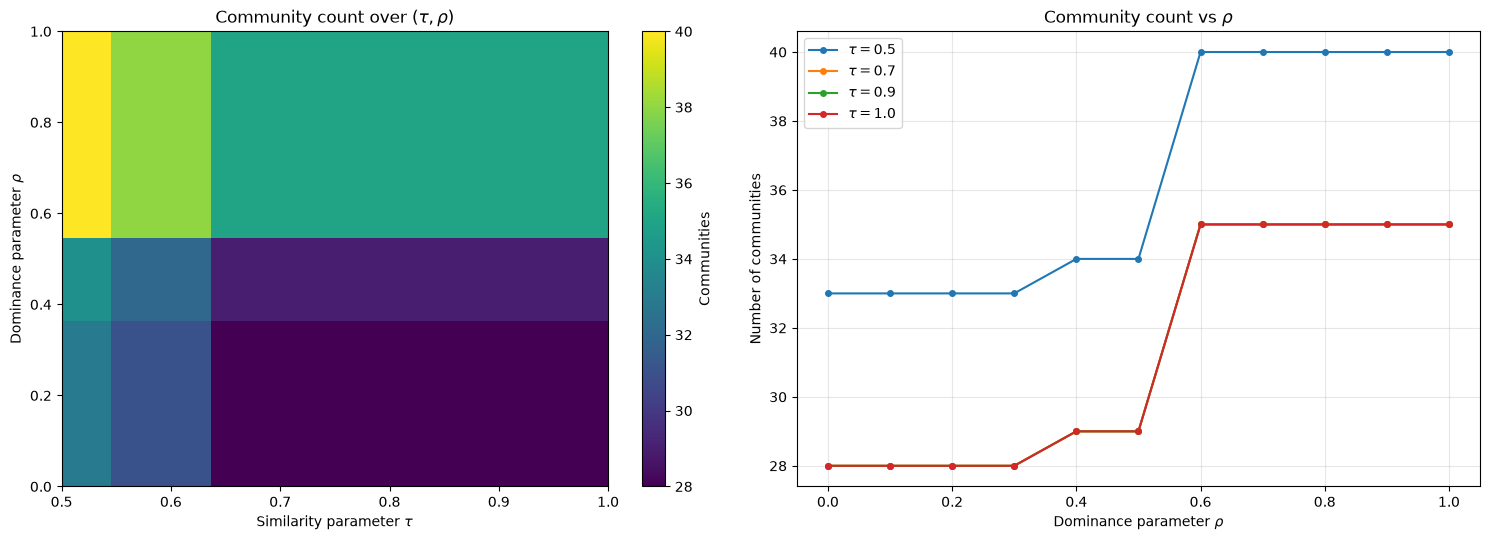

In [83]:
### Visualisation: community count over the (tau, rho) grid ###

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: heatmap of community count
ax = axes[0]
im = ax.imshow(
    surface.values, origin="lower", aspect="auto", cmap="viridis",
    extent=[taus[0], taus[-1], rhos[0], rhos[-1]],
)
ax.set_xlabel(r"Similarity parameter $\tau$")
ax.set_ylabel(r"Dominance parameter $\rho$")
ax.set_title("Community count over $(\\tau, \\rho)$")
fig.colorbar(im, ax=ax, label="Communities")

# Right: count vs rho for selected tau
ax = axes[1]
for t in [0.5, 0.7, 0.9, 1.0]:
    sub = grid_df[grid_df["tau"] == t]
    ax.plot(sub["rho"], sub["communities"], "o-", markersize=4,
            label=rf"$\tau = {t}$")
ax.set_xlabel(r"Dominance parameter $\rho$")
ax.set_ylabel("Number of communities")
ax.set_title(r"Community count vs $\rho$")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

For the `weaver` social interaction netwrok, joint sweep over $(\tau, \rho)$ yields **nine** distinct community counts, namely $\{28, 29, 31, 32, 33, 34, 35, 38, 40\}$, spanning a range of $12$ different values. The grid can be strictly separated, such that when writing $N(\tau, \rho)$ for the estimated count, the entries satisfy

$$
N(\tau,\rho) = f(\tau) + g(\rho), \qquad
f(\tau) \in \{33,\, 31,\, 28\}, \qquad
g(\rho) \in \{0,\, 1,\, 7\},
$$

so the two parameters act on the count **independently and additively**, with no interaction term. The factor $g$ is a step function of $\rho$ with $g = 0$ for $\rho \in [0, 0.3]$, $g = 1$ for $\rho \in [0.4, 0.5]$, and $g = 7$ for $\rho \in [0.6, 1.0]$. Consequently the spread across $\rho$ is **constant at exactly $7$ communities for every value of $\tau$**, which is the cleanest numerical confirmation of the addativity property, stated above. The factor $f$ decreases in $\tau$: $33$ at $\tau = 0.50$, $31$ for $\tau \in \{0.55, 0.60\}$, and then finally $28$ for all $\tau \geq 0.65$ after which it remains completely unchanged for the upper third of the range, so that for $\tau \geq 0.65$ the community count is determined by $\rho$ alone. Since that region comprises most of the permissable values in the grid cells, we can conclude that the estimation algorithm behaviour is entirely determined by the dominance parameter once the similarity threshold is sufficiently large $(\tau \geq 0.65)$. In that situation, the estimate seems to be complete deterministic whenever $\rho \geq 0.6$ (for the specific choice of our network).

### 2.5. General Procedure for Parameter Selection (Selection via Invariance)

Neither parameter can be properly identified via single scalar objective optimisation. Modularity makes $\rho \to 0$ and no statistical measurement can adequately address the parameter choice, which is why we decide to do a sort of *majority vote*, meaning that we select the estimate for the number of communities which is **invariant** over the largest intervals for $\rho$ and $\tau$. Again using the notation $N(\tau,\rho)$ for the estimated count, we will expect the sweep to always be perfectly seprable, so that the grid, composed of premissible values for $\tau$ and $\rho$ decomposes into perfect rectangular regions on each of which $N$ is constant. We call these **plateaus** and the way our selection procedure operates, will be to select the one with the largest area. For example, in the `weaver` network that area was given by 

$$\mathcal{P}^{*} = [0.65, 1.00] \times [0.60, 1.00]\ \text{with}\ |\mathcal{P}^{*}| = 40\ \text{cells}$$

for which $N \equiv 35$ throughout. We claim that as this answer is stable over the widest range of parameter selection, it is therefore also least sensitive to arbitrary parameter choice that may not necessarily reveal information pertaining to the data (or if it does, that information would likely be of unknown character). Within $\mathcal{P}^{*}$ the specific choice of parameters is irrelevant, as they all yield the same result. Moreover, we can use the largest grid area $|\mathcal{P}^{*}|$ in comparison with the entire grid length to express an uncertainty metric in regards to our answer. Going back to the `weaver` network example, this selection procedure would yield the result of $35$ communities, which is stable across $40$ of $121$ parameter combinations, within the full range for community estimates, spannning $28$ to $40$. 

It's important to note that this rule only uses the graph observation and does not introduce no new parameter; however, it does rank the plateaus by area as there is no real way of measuring accuracy, and further for this method to work we do assume the existance of such plateus which is a property, we saw for the `weaver`network, but have not yet verified in general.

In [70]:
### Selection of Largest Area Plateau ###

def run_grid(G, taus, rhos):
    """Community count over the (tau, rho) grid."""
    nodes = list(G.nodes())
    rows = []
    for t in taus:
        _, lab0 = estimate_communities(G, tau=float(t))
        for r in rhos:
            lab1, _ = merge_dominated_singletons(G, lab0, dominance=float(r))
            rows.append({
                "tau": round(float(t), 2),
                "rho": round(float(r), 2),
                "communities": len(community_vsets(lab1, nodes=nodes)),
            })
    return pd.DataFrame(rows)

def select_plateau(surface):
    """Largest rectangular plateau; return its centre and extent."""
    best = None
    for v in np.unique(surface.values):
        mask = surface.values == v
        ri = np.where(mask.any(axis=1))[0]
        ci = np.where(mask.any(axis=0))[0]
        if not mask[np.ix_(ri, ci)].all():      # not a rectangle
            continue
        if best is None or mask.sum() > best["cells"]:
            best = {
                "count": int(v),
                "cells": int(mask.sum()),
                "tau": float(surface.columns[ci[0]] + surface.columns[ci[-1]]) / 2,
                "rho": float(surface.index[ri[0]] + surface.index[ri[-1]]) / 2,
                "tau_range": (float(surface.columns[ci[0]]), float(surface.columns[ci[-1]])),
                "rho_range": (float(surface.index[ri[0]]), float(surface.index[ri[-1]])),
            }
    return best

taus = np.linspace(0.50, 1.00, 11)
rhos = np.linspace(0.00, 1.00, 11)

surface = run_grid(weaver, taus, rhos).pivot(
    index="rho", columns="tau", values="communities"
)
sel = select_plateau(surface)

print(f"tau = {sel['tau']:.3f}, rho = {sel['rho']:.3f}  ->  {sel['count']} communities")
print(f"plateau: tau in {sel['tau_range']}, rho in {sel['rho_range']} ({sel['cells']} cells)")

tau = 0.825, rho = 0.800  ->  35 communities
plateau: tau in (0.65, 1.0), rho in (0.6, 1.0) (40 cells)


### 2.6. Validation Using Stochastic Block Models

To evaluate the effectiveness of our community-count estimator, we test it on networks generated using the stochastic block model (SBM). This model allows us to construct graphs with a known number of planted communities and control how strongly these communities are separated.

We consider SBMs with $K$ equally sized communities. Two vertices within the same community are connected independently with probability $p_{\mathrm{in}}$, while vertices belonging to different communities are connected with probability $p_{\mathrm{out}}$.

When $p_{\mathrm{in}} > p_{\mathrm{out}}$, edges are more likely to occur within communities than between them. Increasing the difference between these probabilities generally makes the planted community structure easier to identify.

For each generated network, we apply our common-neighbour estimator with dominance-based singleton merging with automatic selection of both parameters $(\tau, \rho)$ using the **plateau rule** (Section 2.5), which chooses the centre of the largest rectangular region of the $(\tau, \rho)$ grid where the community count is constant and compares the estimated number of communities $\hat K$ with the planted number $K$.

We investigate how estimation accuracy changes with the number of communities and the strength of their separation. Repeated simulations are used to assess the stability of the estimator and identify situations in which the surface fails to be separable, in which case the procedure falls back to $(\tau, \rho) = (1, 1)$.

In [79]:
### Generate and test stochastic block models ###

SBM_K_VALUES = [2, 4, 6]
SBM_SEPARATIONS = {
    "Weak": 0.04,
    "Moderate": 0.10,
    "Strong": 0.20
}

SBM_N = 240
SBM_P_OUT = 0.01
SBM_REPS = 10
SBM_TAUS = np.linspace(0.50, 1.00, 6)
SBM_RHOS = np.linspace(0.00, 1.00, 6)

rng_sbm = np.random.default_rng(SEED)

def generate_sbm(K, p_in, p_out, n=SBM_N, seed=None):
    sizes = [n // K] * K
    probabilities = np.full((K, K), p_out)
    np.fill_diagonal(probabilities, p_in)
    return nx.stochastic_block_model(sizes, probabilities, seed=seed)

sbm_results = []

for K in SBM_K_VALUES:
    for separation, p_in in SBM_SEPARATIONS.items():
        for rep in range(SBM_REPS):
            G = generate_sbm(K, p_in, SBM_P_OUT, n=SBM_N,
                             seed=int(rng_sbm.integers(0, 2**31)))

            try:
                surface = run_grid(G, SBM_TAUS, SBM_RHOS)
                surf = surface.pivot(index="rho", columns="tau", values="communities")
                sel = select_plateau(surf)
                K_hat, separable = sel["count"], True
            except Exception:
                _, labels = estimate_communities(G, tau=1.0)
                K_hat = len(set(labels))
                separable = False

            sbm_results.append({
                "Planted K": K,
                "Separation": separation,
                "p_in": p_in,
                "Estimated K": K_hat,
                "Absolute error": abs(K_hat - K),
                "Separable": separable,
            })

sbm_df = pd.DataFrame(sbm_results)

summary_sbm = (
    sbm_df.groupby(["Separation", "Planted K"])
    .agg(
        Mean_estimated_K=("Estimated K", "mean"),
        Std_estimated_K=("Estimated K", "std"),
        Mean_absolute_error=("Absolute error", "mean"),
        Separable_fraction=("Separable", "mean")
    )
    .round(2)
)
display(summary_sbm)

Mean_estimated_K  Std_estimated_K  Mean_absolute_error  \
Separation Planted K                                                           
Moderate   2                       1.0             0.00                  1.0   
           4                       4.1             2.08                  1.5   
           6                      84.5            60.78                 78.7   
Strong     2                       1.0             0.00                  1.0   
           4                       1.0             0.00                  3.0   
           6                       1.0             0.00                  5.0   
Weak       2                     155.0            50.08                153.0   
           4                     197.0             5.66                193.0   
           6                     198.2             6.46                192.2   

                      Separable_fraction  
Separation Planted K                      
Moderate   2                         1.0  
           4                         1.0  
           6                         1.0  
Strong     2                         1.0  
           4                         1.0  
           6                         1.0  
Weak       2                         1.0  
           4                         1.0  
           6                         1.0

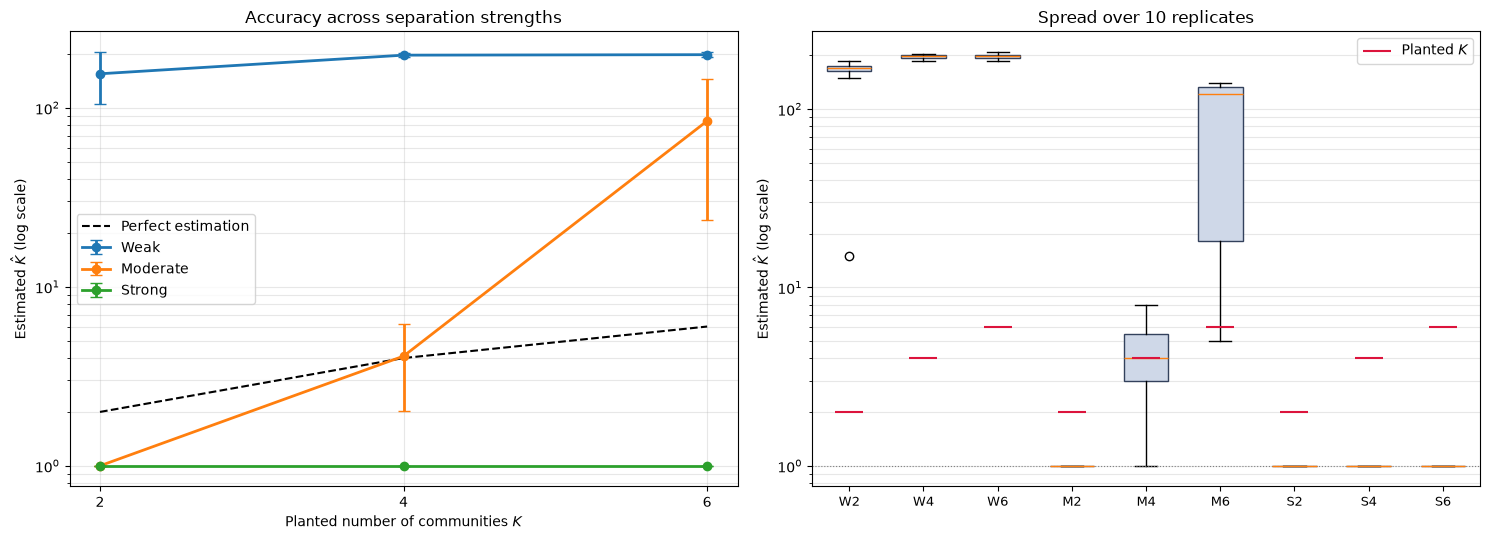

In [76]:
### Accuracy and replicate spread ###

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) mean +/- std, log scale
ax = axes[0]
for sep in SBM_SEPARATIONS:
    sub = (sbm_df[sbm_df["Separation"] == sep]
           .groupby("Planted K")["Estimated K"].agg(["mean", "std"]))
    ax.errorbar(sub.index, sub["mean"], yerr=sub["std"],
                marker="o", capsize=4, linewidth=2, label=sep)

ax.plot(SBM_K_VALUES, SBM_K_VALUES, "k--", label="Perfect estimation")
ax.set_yscale("log")
ax.set_xticks(SBM_K_VALUES)
ax.set_xlabel("Planted number of communities $K$")
ax.set_ylabel(r"Estimated $\hat K$ (log scale)")
ax.set_title("Accuracy across separation strengths")
ax.grid(alpha=0.3, which="both")
ax.legend()

# (b) replicate distributions
ax = axes[1]
groups = [(sep, K) for sep in SBM_SEPARATIONS for K in SBM_K_VALUES]
positions = np.arange(len(groups))
data = [sbm_df[(sbm_df["Separation"] == s) &
               (sbm_df["Planted K"] == k)]["Estimated K"].values
        for s, k in groups]

bp = ax.boxplot(data, positions=positions, widths=0.6,
                patch_artist=True, showfliers=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#cfd8e8")
    patch.set_edgecolor("#33415c")

ax.scatter(positions, [k for _, k in groups], marker="_", s=400,
           color="crimson", zorder=3, label="Planted $K$")

ax.set_yscale("log")
ax.set_xticks(positions)
ax.set_xticklabels([f"{s[0]}{k}" for s, k in groups], fontsize=9)
ax.axhline(1, color="gray", lw=0.8, ls=":")
ax.set_ylabel(r"Estimated $\hat K$ (log scale)")
ax.set_title("Spread over 10 replicates")
ax.grid(alpha=0.3, which="both", axis="y")
ax.legend()

plt.tight_layout()
plt.show()

### 2.7 Diagnostic Tests & Preliminary Results

#### 2.7.1. Diagnostic (K = 6)

In [77]:
# Inspect the surface for a single Strong-separation instance
Gs = generate_sbm(6, SBM_SEPARATIONS["Strong"], SBM_P_OUT, n=SBM_N, seed=0)
surf_diag = (run_grid(Gs, SBM_TAUS, SBM_RHOS)
             .pivot(index="rho", columns="tau", values="communities"))
display(surf_diag)
print("planted K =", 6)

tau,0.5,0.6,0.7,0.8,0.9,1.0
rho,,,,,,
0.0,1,1,1,1,1,1
0.2,1,1,1,1,1,1
0.4,1,1,1,1,1,1
0.6,1,1,1,1,1,1
0.8,1,1,1,1,1,1
1.0,3,3,3,3,3,3


planted K = 6


#### 2.7.2 Strong Separation Failure

Surprisingly, the estimator performs the worst under **strong** separation ($p_{\mathrm{in}} = 0.20$, $p_{\mathrm{out}} = 0.01$), returning exactly one community for all $K \in \{2,\ 4,\ 6\}$. Upon further investigation into the similarity graph, we can deduce that the cause likely is because every adjacent pair of vertices shares at least one common neighbour, including cross-block edges. With $n / K = 40$ vertices per block, each vertex expects approximately $39 \times 0.20 = 7.8$ intra-block edges and $200 \times 0.01 = 2.0$ cross-block edges. The expected number of common neighbours for cross-block adjacent pairs is approximately 

$$(K-1)(n/K)p_{\mathrm{out}}^2 \approx 5 \times 40 \times 0.0001 \approx 0.02,$$

yet the realised data shows $1.04$ common neighbours per cross-block edge. This indicates that cross-block edges connect vertices whose intra-block connections create shared neighbours, causing the similarity graph to retain essentially all edges from $G$ rather than filtering to intra-block structure. The result is a giant component containing all 6 planted blocks fused together, with the estimator collapsing to a single community. This is a **structural limitation** of our common-neighbour assumption as it fails precisely when dense intra-block structure generate higher indirect common-neighbour paths across planted boundaries.

## 3. Empirical Testing on Real-Life Network

### 3.1. Weaver Social Interaction Network

For our choice of network, we decided on `aver-weaver-social`, in which network:

- Nodes represent individual birds
- Edges represent observed social interactions

Due to the nature of this network we would expect naturally communities to occur due to geographical reasons and genetical or familial relations. Likely communities would represent:

- Different bird flocks or family groups *(social structure)*
- Potential kinship groups or breeding pairs *(bloodline relation)*
- Birds that spend time together in the same territory *(geographical proximity)*

### 3.2. Network Properties Analysis

In [37]:
def describe_network(G, name):
    degree_list = np.array([deg for _, deg in G.degree()])
    print(f"Computing network {name}")
    return {"network": name, "n": G.number_of_nodes(), "m": G.number_of_edges(),
            "mean degree": degree_list.mean(), "max degree": int(degree_list.max()),
            "leaves": int((degree_list == 1).sum()),
            "isolated vertices": int((degree_list == 0).sum()),
            "interactions": nx.number_connected_components(G),
            "avg clustering coeff.": nx.average_clustering(G),
            "assortativity": nx.degree_assortativity_coefficient(G),
            "transitivity": nx.transitivity(G)}

display(pd.DataFrame([describe_network(weaver, "Social Weaver Network")]).set_index("network"))

Computing network Social Weaver Network


,n,m,mean degree,max degree,leaves,isolated vertices,interactions,avg clustering coeff.,assortativity,transitivity
network,,,,,,,,,,
Social Weaver Network,445,1332,5.986517,27,41,0,22,0.668505,0.199066,0.588094


### 3.3 Predictions Based on Network Properties

The average local clustering coefficient is $0.669$ and the global transitivity is $0.588$ which are both very high, indicating likely presence of many triangles, so neighbours of a vertex are themselves usually adjacent which means that this likely improves the chances for higher accuracy of our estimation procedure. The difference between the two values ($0.081$) can be interpreted as percentage of "scale-free"-ness in the network, so a smaller difference implies a more uniform network structure. Degree assortativity is mildly positive at $0.199$, so high-degree vertices tend to attach to other high-degree vertices.

As noted before, it is likely that $M_{uv} > 0$ for most edges and that the similarity graph $S$ retains a large fraction of $E$. Therefore, we expect the estimator to be well-conditioned on this example in contrast to the SBM model. As $M = (A^2)\odot A$ has non-zeros only on adjacent pairs, $S$ is a subgraph of $G$, so every component of $S$ lies inside a component of $G$. The estimator can therefore never return fewer than $22$ communities, and the singleton-merge operator cannot lower this bound either as it absorbs singletons only into already existing communities.

We now estimate the community count using the procedure of Problem 1, apply spectral clustering at the estimated $K$, and compare the result with Louvain.

In [92]:
### Community count via the plateau rule (Section 2.4) ###

G = weaver
print("G:", G)
print("components:", nx.number_connected_components(G))

nodes = list(G.nodes())

taus = np.linspace(0.50, 1.00, 11)
rhos = np.linspace(0.00, 1.00, 11)

surface = run_grid(G, taus, rhos).pivot(
    index="rho", columns="tau", values="communities"
)
sel = select_plateau(surface)

tau_selected, rho_selected = sel["tau"], sel["rho"]

_, labels_tau = estimate_communities(G, tau=tau_selected)
labels, n_merged = merge_dominated_singletons(G, labels_tau, dominance=rho_selected)
estimated_communities = community_vsets(labels, nodes=nodes)
K_estimated = len(estimated_communities)

print("Selected tau:", tau_selected)
print("Selected rho:", rho_selected)
print("Estimated number of communities:", K_estimated)
print("Estimated community sizes:", sorted([len(c) for c in estimated_communities]))
print("Plateau extent: tau in", sel["tau_range"], ", rho in", sel["rho_range"])

# Lower bound implied by the component structure of G
n_comp_G = nx.number_connected_components(G)
print(f"\nComponents of G: {n_comp_G}")
print(f"Lower bound respected: {K_estimated >= n_comp_G}")

G: Graph with 445 nodes and 1332 edges
components: 22
Selected tau: 0.825
Selected rho: 0.8
Estimated number of communities: 35
Estimated community sizes: [1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 4, 4, 4, 4, 4, 4, 5, 5, 5, 6, 7, 7, 7, 10, 11, 11, 24, 42, 43, 45, 64, 103]
Plateau extent: tau in (0.65, 1.0) , rho in (0.6, 1.0)

Components of G: 22
Lower bound respected: True


### 3.4. Spectral Clustering Implementation

In [93]:
nodes = list(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)

spectral = SpectralClustering(n_clusters=K_estimated, affinity="precomputed", assign_labels="kmeans",n_init=20)

spectral_labels = spectral.fit_predict(A)

spectral_communities = [{nodes[i] for i in range(len(nodes)) if spectral_labels[i] == c} for c in range(K_estimated)]

print("Spectral clustering")
print("Number of communities:", len(spectral_communities))
print("Community sizes:", sorted([len(c) for c in spectral_communities], reverse=True))

c:\Users\HP\Documents\TUe\@ Y3\@ Q1\CN\Project 3\Group_20_Project_3\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Spectral clustering
Number of communities: 35
Community sizes: [48, 45, 36, 33, 27, 27, 26, 17, 16, 13, 11, 11, 11, 11, 10, 9, 8, 8, 7, 7, 7, 7, 6, 6, 5, 4, 4, 4, 4, 4, 4, 3, 2, 2, 2]


### 3.5. Louvain Implementation

(Louvain) Number of communities: 28
(Louvain) Community sizes: [45, 43, 41, 36, 35, 30, 26, 25, 24, 18, 15, 13, 11, 11, 10, 10, 9, 7, 6, 5, 4, 4, 4, 4, 3, 2, 2, 2]


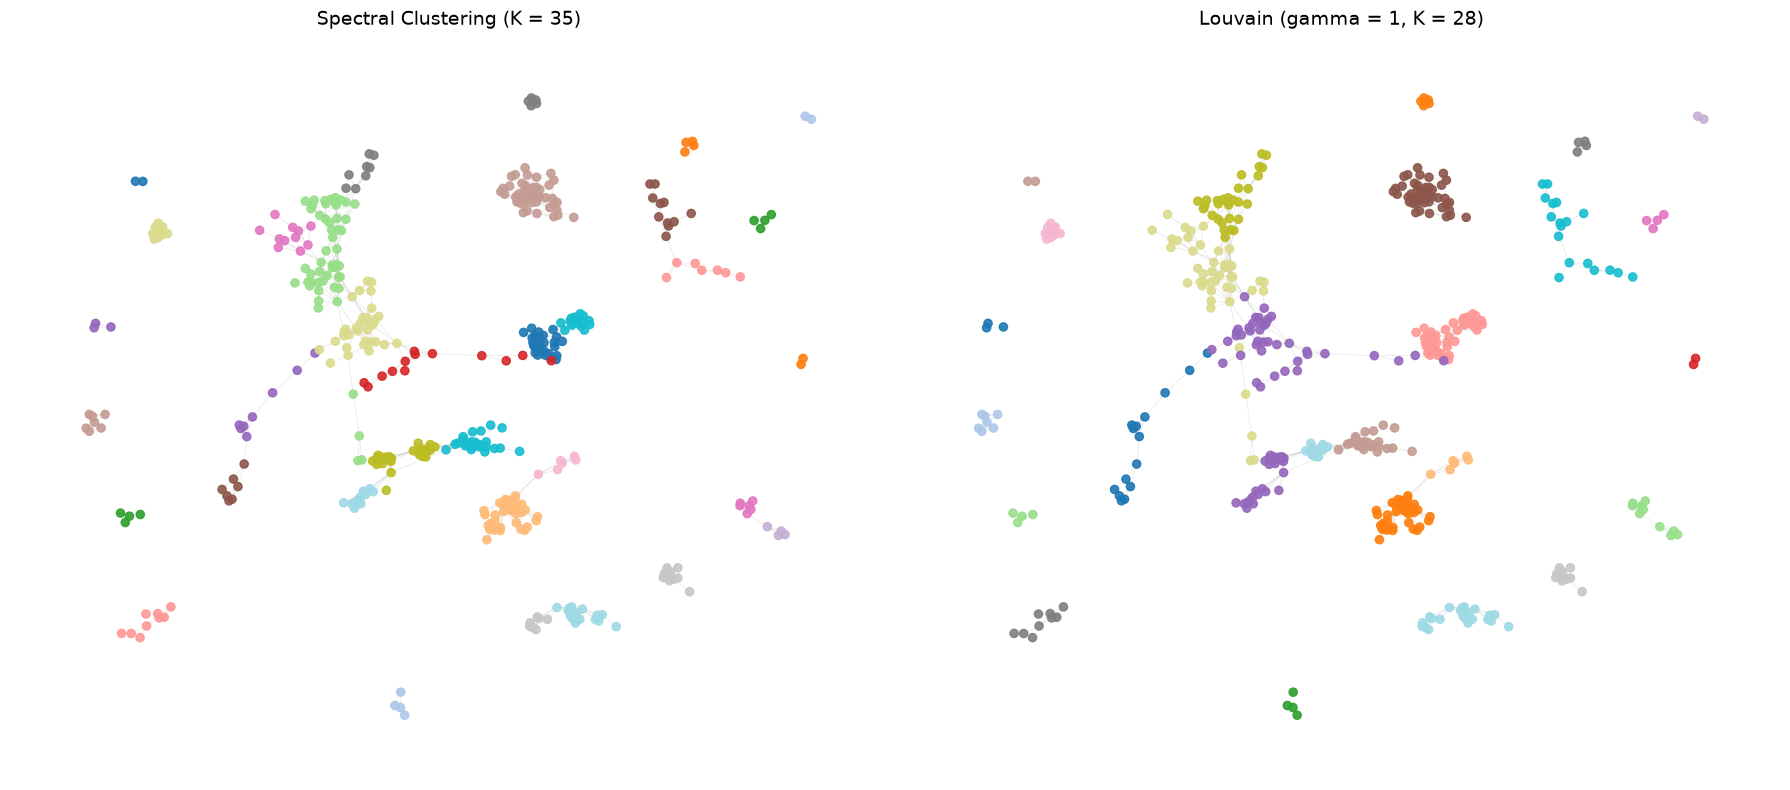

In [94]:
louvain_communities = [set(c) for c in nx.community.louvain_communities(G)]

def make_label_dict(communities, nodes):
    """Create mapping that labels nodes according to a given community partition."""
    label_dict = {}
    for idx, comm in enumerate(communities):
        for v in comm:
            label_dict[v] = idx
    uncovered = [v for v in nodes if v not in label_dict]
    if uncovered:
        raise ValueError(
            f"{len(uncovered)} node(s) not covered by the partition, "
            f"e.g. {uncovered[:5]}"
        )
    return label_dict

def node_color_list(label_dict, nodes, cmap_name="tab20"):
    """Define a colour list which returns a colour for each community."""
    n_comm = max(label_dict.values()) + 1
    palette = plt.get_cmap(cmap_name, n_comm)   # n_comm discrete colours
    return [palette(label_dict[v]) for v in nodes]

nodes = list(G.nodes())

# spectral_communities from 3.4. Spectral Clustering Implementation
spectral_label_by_node = make_label_dict(spectral_communities, nodes)
louvain_label_by_node  = make_label_dict(louvain_communities, nodes)


print("(Louvain) Number of communities:", len(louvain_communities))
print("(Louvain) Community sizes:",sorted([len(c) for c in louvain_communities], reverse=True))

pos = nx.spring_layout(G, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

partitions = [
    (axes[0], spectral_label_by_node, f"Spectral Clustering (K = {len(spectral_communities)})"),
    (axes[1], louvain_label_by_node, f"Louvain (gamma = 1, K = {len(louvain_communities)})"),
]

for ax, labels, title in partitions:
    # node_colors = [labels[node] for node in G.nodes()]
    node_colors = node_color_list(labels, nodes)

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        alpha=0.2,
        width=0.5,
        edge_color="gray"
    )

    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_color=node_colors,
        node_size=35,
        alpha=0.9
    )

    # nx.draw_networkx_nodes(G, pos, ax=ax,node_color=node_colors, cmap="tab20", node_size=35,alpha=0.9)

    ax.set_title(title, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
### Resolution sweep for Louvain (defines gamma_df) ###

GAMMA_GRID = np.linspace(0.1, 2.0, 20)
gamma_results = []

for gamma in GAMMA_GRID:
    louvain_gamma = nx.community.louvain_communities(G, resolution=float(gamma), seed=SEED)
    louvain_sets = [set(c) for c in louvain_gamma]
    sizes = np.array([len(c) for c in louvain_sets])

    gamma_results.append({
        "gamma": float(gamma),
        "num_communities": len(louvain_sets),
        "mean_size": sizes.mean(),
        "size_std": sizes.std(),
        "modularity": nx.community.modularity(G, louvain_sets),  # Q at gamma = 1, see note
    })

gamma_df = pd.DataFrame(gamma_results)
display(gamma_df.round(3))

,gamma,num_communities,mean_size,size_std,modularity
0,0.1,1,240.0,0.000,0.000
1,0.2,1,240.0,0.000,0.000
2,0.3,4,60.0,20.000,0.563
3,0.4,6,40.0,0.577,0.641
4,0.5,6,40.0,0.577,0.641
5,0.6,6,40.0,0.577,0.641
6,0.7,6,40.0,0.577,0.641
7,0.8,6,40.0,0.577,0.641
8,0.9,6,40.0,0.577,0.641
9,1.0,6,40.0,0.577,0.641


### 3.6. Agreement Metric

$$\mu(\mathcal{C}, \mathcal{C'}) = \frac{\sum_{\gamma \in \Gamma} \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C}) \times \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C'})}{\sqrt{\sum_{\gamma \in \Gamma} \left( \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C}) \right)^2 \times \sqrt{\sum_{\gamma \in \Gamma} \left( \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C'}) \right)^2}}}$$

where $\mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C})$ is the configuration model modularity, given by:

$$\mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C}) \coloneqq \frac{1}{2|E|} \sum_{i = 1}^{k} \sum_{v, w \in C_i} \left( I_{vw} - \gamma \frac{d_v d_w}{2|E|} \right)$$

In [95]:
### Define Configuration Model Modularity ###

def validate_partition(G, communities):
    """Ensure communities is a genuine partition of V(G)"""
    seen = set()
    for comm in communities:
        comm = set(comm)
        overlap = seen & comm
        if overlap:
            raise ValueError(f"Partition overlaps on {sorted(overlap)[:5]} ...")
        seen |= comm
    missing = set(G.nodes()) - seen
    if missing:
        raise ValueError(f"Partition misses {len(missing)} nodes, e.g. {sorted(missing)[:5]}")


def configuration_modularity(G, communities, gamma=1.0):
    """
    Configuration model modularity at resolution gamma.
    Calculated as a - gamma * b, where 
        a = (sum over all communities of {# intra-community edges}) / (total # of edges)
        b = sum over all communities of {[(sum of all community degrees) / [2 * (total # of edge)]^2}
    """
    m = G.number_of_edges()
    if m == 0:
        raise ValueError("Modularity is undefined for a graph with no edges.")
    validate_partition(G, communities)

    degree = dict(G.degree())
    a = 0.0
    b = 0.0
    for comm in communities:
        members = set(comm)
        K_c = sum(degree[v] for v in members)
        m_c = G.subgraph(members).number_of_edges()   # internal edges, counted once
        a += m_c / m
        b += (K_c / (2.0 * m)) ** 2
    return a - gamma * b

_check = [set(c) for c in nx.community.louvain_communities(G, seed=SEED)]

manual_q = configuration_modularity(G, _check, gamma=1.0)
nx_q = nx.community.modularity(G, _check)

print(f"manual  Q (gamma=1) = {manual_q:.8f}")
print(f"networkx Q (gamma=1) = {nx_q:.8f}")
print(f"absolute difference = {abs(manual_q - nx_q):.2e}")

manual  Q (gamma=1) = 0.89503439
networkx Q (gamma=1) = 0.89503439
absolute difference = 1.11e-16


In [96]:
### Agreement Metric Implementation ###

GAMMAS = np.linspace(0.05, 2.5, 250) # range of gammas in the set Г

def modularity_vec(G, communities, gammas=GAMMAS):
    """Vector of M^CM(gamma, C) over the premissible values for gamma in GAMMAS."""
    return np.array([configuration_modularity(G, communities, g) for g in gammas], dtype=float)

def mu(G, partition_a, partition_b, gammas=GAMMAS):
    """
    Agreement metric, given by the cosine similarity of the modularities over gammas for the two partitions.
    
    mu(C, C') = <p(C), p(C')> / (||p(C)|| * ||p(C')||)
    """
    modularities_a = modularity_vec(G, partition_a, gammas) # modularities of partition a over gammas
    modularities_b = modularity_vec(G, partition_b, gammas) # modularities of partition b over gammas
    denominator = np.linalg.norm(modularities_a) * np.linalg.norm(modularities_b)
    if denominator == 0.0:
        return np.nan
    numerator = np.dot(modularities_a, modularities_b)
    return float(numerator / denominator)

### 3.7. Empirical Verification

,Spectral (K-hat),Louvain (gamma=1),Louvain (gamma=1.70)
Spectral (K-hat),1.0,1.0000,1.0000
Louvain (gamma=1),1.0,1.0000,0.9999
Louvain (gamma=1.70),1.0,0.9999,1.0000


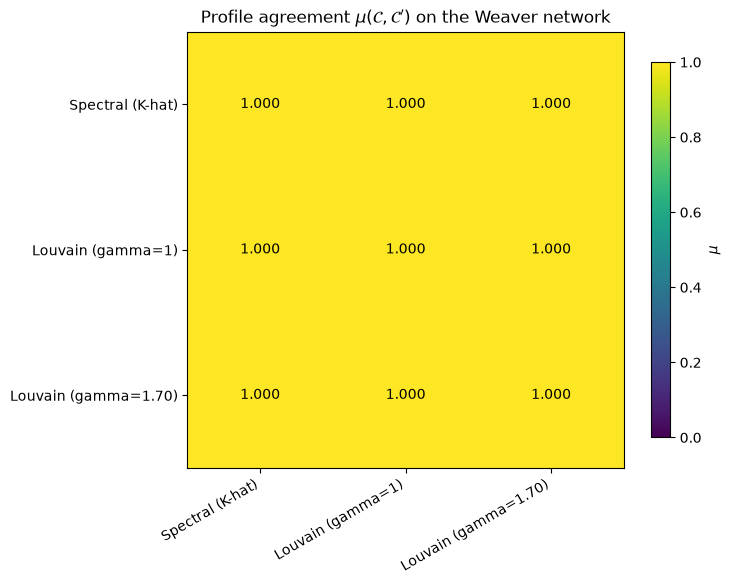

In [97]:
### Applying mu to the Weaver network ###

# Louvain at the modularity-selected resolution (from the gamma sweep)
OPTIMAL_GAMMA = float(gamma_df.loc[gamma_df["modularity"].idxmax(), "gamma"])
louvain_selected = [set(c) for c in
                    nx.community.louvain_communities(G, resolution=OPTIMAL_GAMMA, seed=SEED)]

named_partitions = {
    "Spectral (K-hat)": [set(c) for c in spectral_communities],
    "Louvain (gamma=1)": [set(c) for c in louvain_communities],
    f"Louvain (gamma={OPTIMAL_GAMMA:.2f})": louvain_selected,
}

# MU Matrix for Comparison of Different Partition Methods
names = list(named_partitions)
MU = np.eye(len(names))
for i, ni in enumerate(names):
    for j, nj in enumerate(names):
        if j > i:
            MU[i, j] = MU[j, i] = mu(G, named_partitions[ni], named_partitions[nj])

mu_df = pd.DataFrame(MU, index=names, columns=names)
display(mu_df.round(4))

# Heatmap Visualization of Method Comparison
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(mu_df.values, vmin=0.0, vmax=1.0, cmap="viridis")
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticklabels(names)

for i in range(len(names)):
    for j in range(len(names)):
        val = mu_df.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                color="white" if val < 0.65 else "black", fontsize=10)

ax.set_title(r"Profile agreement $\mu(\mathcal{C},\mathcal{C}')$ on the Weaver network")
fig.colorbar(im, ax=ax, label=r"$\mu$", shrink=0.85)
plt.tight_layout()
plt.show()